In [2]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
from datetime import datetime, timedelta
from dateutil.relativedelta import relativedelta
import pprint
import pyspark
import pyspark.sql.functions as F

from pyspark.sql.functions import col
from pyspark.sql.types import StringType, IntegerType, FloatType, DateType, DecimalType

import utils.data_processing_bronze
import utils.data_processing_silver
import utils.data_processing_gold


## set up pyspark session

In [57]:
print("#"*50 + "\n")

##################################################



In [3]:
# Initialize SparkSession
spark = pyspark.sql.SparkSession.builder \
    .appName("dev") \
    .master("local[*]") \
    .getOrCreate()

# Set log level to ERROR to hide warnings
spark.sparkContext.setLogLevel("ERROR")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/09/28 14:19:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## set up config

In [16]:
# set up config
snapshot_date_str = "2023-01-01"

start_date_str = "2023-01-01"
end_date_str = "2023-03-01"

In [7]:
# generate list of dates to process
def generate_first_of_month_dates(start_date_str, end_date_str):
    # Convert the date strings to datetime objects
    start_date = datetime.strptime(start_date_str, "%Y-%m-%d")
    end_date = datetime.strptime(end_date_str, "%Y-%m-%d")
    
    # List to store the first of month dates
    first_of_month_dates = []

    # Start from the first of the month of the start_date
    current_date = datetime(start_date.year, start_date.month, 1)

    while current_date <= end_date:
        # Append the date in yyyy-mm-dd format
        first_of_month_dates.append(current_date.strftime("%Y-%m-%d"))
        
        # Move to the first of the next month
        if current_date.month == 12:
            current_date = datetime(current_date.year + 1, 1, 1)
        else:
            current_date = datetime(current_date.year, current_date.month + 1, 1)

    return first_of_month_dates

dates_str_lst = generate_first_of_month_dates(start_date_str, end_date_str)
dates_str_lst

['2023-01-01', '2023-02-01', '2023-03-01']

## Build Bronze Table

In [10]:
# create bronze datalake
bronze_lms_directory = "datamart/bronze/lms/"

bronze_clickstream_directory = "datamart/bronze/feature_clickstream/"
bronze_attributes_directory = "datamart/bronze/features_attributes/"
bronze_financials_directory = "datamart/bronze/features_financials/"

if not os.path.exists(bronze_lms_directory):
    os.makedirs(bronze_lms_directory)

if not os.path.exists(bronze_clickstream_directory):
    os.makedirs(bronze_clickstream_directory)

if not os.path.exists(bronze_attributes_directory):
    os.makedirs(bronze_attributes_directory)

if not os.path.exists(bronze_financials_directory):
    os.makedirs(bronze_financials_directory)



In [34]:
# define the bronze file

lms_file = "data/lms_loan_daily.csv"
clickstream_file = "data/feature_clickstream.csv"
attributes_file = "data/features_attributes.csv"
financials_file = "data/features_financials.csv"

In [7]:
#reload lib after changing the code

import importlib
import utils.data_processing_bronze_table
importlib.reload(utils.data_processing_bronze)

<module 'utils.data_processing_bronze_table' from '/app/utils/data_processing_bronze_table.py'>

In [35]:
# run bronze backfill for lms_file
for date_str in dates_str_lst:
    utils.data_processing_bronze.process_bronze_table(date_str, lms_file, bronze_lms_directory, spark)


2023-01-01row count: 530
saved to: datamart/bronze/lms/bronze_daily_2023_01_01.csv
2023-02-01row count: 1031
saved to: datamart/bronze/lms/bronze_daily_2023_02_01.csv
2023-03-01row count: 1537
saved to: datamart/bronze/lms/bronze_daily_2023_03_01.csv


In [36]:
# inspect output
utils.data_processing_bronze.process_bronze_table(date_str, lms_file, bronze_lms_directory, spark).toPandas()

2023-03-01row count: 1537
saved to: datamart/bronze/lms/bronze_daily_2023_03_01.csv


,loan_id,Customer_ID,loan_start_date,tenure,installment_num,loan_amt,due_amt,paid_amt,overdue_amt,balance,snapshot_date
0,CUS_0x1037_2023_01_01,CUS_0x1037,2023-01-01,10,2,10000,1000.0,1000.0,0.0,8000.0,2023-03-01
1,CUS_0x1069_2023_01_01,CUS_0x1069,2023-01-01,10,2,10000,1000.0,1000.0,0.0,8000.0,2023-03-01
2,CUS_0x10aa_2023_02_01,CUS_0x10aa,2023-02-01,10,1,10000,1000.0,1000.0,0.0,9000.0,2023-03-01
3,CUS_0x10bb_2023_03_01,CUS_0x10bb,2023-03-01,10,0,10000,0.0,0.0,0.0,10000.0,2023-03-01
4,CUS_0x10eb_2023_03_01,CUS_0x10eb,2023-03-01,10,0,10000,0.0,0.0,0.0,10000.0,2023-03-01
...,...,...,...,...,...,...,...,...,...,...,...
1532,CUS_0xfa7_2023_03_01,CUS_0xfa7,2023-03-01,10,0,10000,0.0,0.0,0.0,10000.0,2023-03-01
1533,CUS_0xfac_2023_03_01,CUS_0xfac,2023-03-01,10,0,10000,0.0,0.0,0.0,10000.0,2023-03-01
1534,CUS_0xfae_2023_03_01,CUS_0xfae,2023-03-01,10,0,10000,0.0,0.0,0.0,10000.0,2023-03-01
1535,CUS_0xfc9_2023_01_01,CUS_0xfc9,2023-01-01,10,2,10000,1000.0,0.0,1000.0,9000.0,2023-03-01


In [44]:
# run bronze backfill for clickstream feature files
for date_str in dates_str_lst:
    utils.data_processing_bronze.process_bronze_table(date_str, clickstream_file, bronze_clickstream_directory, spark)

2023-01-01row count: 8974
saved to: datamart/bronze/feature_clickstream/bronze_daily_2023_01_01.csv
2023-02-01row count: 8974
saved to: datamart/bronze/feature_clickstream/bronze_daily_2023_02_01.csv
2023-03-01row count: 8974
saved to: datamart/bronze/feature_clickstream/bronze_daily_2023_03_01.csv


In [11]:
#Inspect output
utils.data_processing_bronze.process_bronze_table(date_str, clickstream_file, bronze_clickstream_directory, spark).toPandas()

NameError: name 'date_str' is not defined

In [45]:
# run bronze backfill for feature attributes file
for date_str in dates_str_lst:
    utils.data_processing_bronze.process_bronze_table(date_str, attributes_file, bronze_attributes_directory, spark)

2023-01-01row count: 530
saved to: datamart/bronze/features_attributes/bronze_daily_2023_01_01.csv
2023-02-01row count: 501
saved to: datamart/bronze/features_attributes/bronze_daily_2023_02_01.csv
2023-03-01row count: 506
saved to: datamart/bronze/features_attributes/bronze_daily_2023_03_01.csv


In [46]:
# run bronze backfill for feature financials file
for date_str in dates_str_lst:
    utils.data_processing_bronze.process_bronze_table(date_str, financials_file, bronze_financials_directory, spark)

2023-01-01row count: 530
saved to: datamart/bronze/features_financials/bronze_daily_2023_01_01.csv
2023-02-01row count: 501
saved to: datamart/bronze/features_financials/bronze_daily_2023_02_01.csv
2023-03-01row count: 506
saved to: datamart/bronze/features_financials/bronze_daily_2023_03_01.csv


## Build Silver Table

In [5]:
# create silver datalake for lms
silver_lms_daily_directory = "datamart/silver/lms_loan_daily/"

if not os.path.exists(silver_lms_daily_directory):
    os.makedirs(silver_lms_daily_directory)

# create silver datalake for attributes
silver_attributes_daily_directory = "datamart/silver/features_attributes/"

if not os.path.exists(silver_attributes_daily_directory):
    os.makedirs(silver_attributes_daily_directory)

# create silver datalake for financials
silver_financials_daily_directory = "datamart/silver/features_financials/"

if not os.path.exists(silver_financials_daily_directory):
    os.makedirs(silver_financials_daily_directory)

# create silver datalake for clickstream
silver_clickstream_daily_directory = "datamart/silver/features_clickstream/"

if not os.path.exists(silver_clickstream_daily_directory):
    os.makedirs(silver_clickstream_daily_directory)


In [39]:
# run silver backfill for lms
for date_str in dates_str_lst:
    utils.data_processing_silver.process_lms(date_str, bronze_lms_directory, silver_lms_daily_directory, spark)


loaded from: datamart/bronze/lms/bronze_daily_2023_01_01.csv row count: 530
saved to: datamart/silver/lms_loan_daily/silver_loan_daily_2023_01_01.parquet
loaded from: datamart/bronze/lms/bronze_daily_2023_02_01.csv row count: 1031
saved to: datamart/silver/lms_loan_daily/silver_loan_daily_2023_02_01.parquet
loaded from: datamart/bronze/lms/bronze_daily_2023_03_01.csv row count: 1537
saved to: datamart/silver/lms_loan_daily/silver_loan_daily_2023_03_01.parquet


In [24]:
utils.data_processing_silver.process_lms("2023-01-01", bronze_lms_directory, silver_lms_daily_directory, spark).toPandas()

loaded from: datamart/bronze/lms/bronze_daily_2023_01_01.csv row count: 530
saved to: datamart/silver/lms_loan_daily/silver_loan_daily_2023_01_01.parquet


,loan_id,Customer_ID,loan_start_date,tenure,installment_num,loan_amt,due_amt,paid_amt,overdue_amt,balance,snapshot_date,mob,installments_missed,first_missed_date,dpd
0,CUS_0x1037_2023_01_01,CUS_0x1037,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0
1,CUS_0x1069_2023_01_01,CUS_0x1069,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0
2,CUS_0x114a_2023_01_01,CUS_0x114a,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0
3,CUS_0x1184_2023_01_01,CUS_0x1184,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0
4,CUS_0x1297_2023_01_01,CUS_0x1297,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,CUS_0xe98_2023_01_01,CUS_0xe98,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0
526,CUS_0xea6_2023_01_01,CUS_0xea6,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0
527,CUS_0xed3_2023_01_01,CUS_0xed3,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0
528,CUS_0xed8_2023_01_01,CUS_0xed8,2023-01-01,10,0,10000.0,0.0,0.0,0.0,10000.0,2023-01-01,0,0,None,0


In [42]:
# run silver backfill for attributes
for date_str in dates_str_lst:
    utils.data_processing_silver.process_attributes(date_str, bronze_attributes_directory, silver_attributes_daily_directory, spark)


loaded from: datamart/bronze/features_attributes/bronze_daily_2023_01_01.csv row count: 530
saved to: datamart/silver/features_attributes/silver_daily_2023_01_01.parquet
loaded from: datamart/bronze/features_attributes/bronze_daily_2023_02_01.csv row count: 501
saved to: datamart/silver/features_attributes/silver_daily_2023_02_01.parquet
loaded from: datamart/bronze/features_attributes/bronze_daily_2023_03_01.csv row count: 506
saved to: datamart/silver/features_attributes/silver_daily_2023_03_01.parquet


In [19]:
utils.data_processing_silver.process_attributes(date_str, bronze_attributes_directory, silver_attributes_daily_directory, spark).toPandas()

loaded from: datamart/bronze/features_attributes/bronze_daily_2023_03_01.csv row count: 506
saved to: datamart/silver/features_attributes/silver_daily_2023_03_01.parquet


,Customer_ID,Name,Age,SSN,Occupation,snapshot_date
0,CUS_0x10bb,Chyenf,35.0,075-30-4340,Journalist,2023-03-01
1,CUS_0x10eb,Yaob,51.0,#F%$D@*&8,Journalist,2023-03-01
2,CUS_0x1132,Jonathano,39.0,152-95-7926,Mechanic,2023-03-01
3,CUS_0x1135,Baertleinc,22.0,897-95-1425,Journalist,2023-03-01
4,CUS_0x11c7,raden Reddallh,53.0,646-19-1493,Architect,2023-03-01
...,...,...,...,...,...,...
501,CUS_0xf21,Greg Roumeliotise,39.0,040-81-5039,Media_Manager,2023-03-01
502,CUS_0xf4d,Yuntaor,20.0,855-72-4023,Lawyer,2023-03-01
503,CUS_0xfa7,Joseph Axe,35.0,703-73-1678,Entrepreneur,2023-03-01
504,CUS_0xfac,Gregv,32.0,058-63-9425,Manager,2023-03-01


In [23]:
import importlib
importlib.reload(utils.data_processing_silver)
#importlib.reload(utils.data_processing_gold_table)

<module 'utils.data_processing_silver' from '/app/utils/data_processing_silver.py'>

In [47]:
# run silver backfill for financials
for date_str in dates_str_lst:
    utils.data_processing_silver.process_financials(date_str, bronze_financials_directory, silver_financials_daily_directory, spark)


loaded from: datamart/bronze/features_financials/bronze_daily_2023_01_01.csv row count: 530
saved to: datamart/silver/features_financials/silver_daily_2023_01_01.parquet
loaded from: datamart/bronze/features_financials/bronze_daily_2023_02_01.csv row count: 501
saved to: datamart/silver/features_financials/silver_daily_2023_02_01.parquet
loaded from: datamart/bronze/features_financials/bronze_daily_2023_03_01.csv row count: 506
saved to: datamart/silver/features_financials/silver_daily_2023_03_01.parquet


In [25]:
utils.data_processing_silver.process_financials("2023-01-01", bronze_financials_directory, silver_financials_daily_directory, spark).toPandas()

loaded from: datamart/bronze/features_financials/bronze_daily_2023_01_01.csv row count: 530
saved to: datamart/silver/features_financials/silver_daily_2023_01_01.parquet


,Customer_ID,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,...,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,snapshot_date,Credit_History_Age_Months
0,CUS_0x1037,15989.09,1086.42,5,4,2,4.0,"Credit-Builder Loan, Auto Loan, Auto Loan, and...",13,15,...,665.82,40.70,19 Years and 9 Months,No,33.80,80.47,Low_spent_Small_value_payments,284.38,2023-01-01,237
1,CUS_0x1069,58637.34,4799.45,4,6,10,119.0,"Personal Loan, Auto Loan, and Not Specified",9,17,...,208.80,25.23,30 Years and 8 Months,Yes,139.89,165.21,High_spent_Small_value_payments,434.85,2023-01-01,368
2,CUS_0x114a,15305.46,1230.46,0,7,2,2.0,"Student Loan, and Home Equity Loan",14,2,...,642.42,27.53,15 Years and 9 Months,No,20.30,64.78,Low_spent_Small_value_payments,327.97,2023-01-01,189
3,CUS_0x1184,19867.48,1396.62,3,5,11,3.0,"Student Loan, Mortgage Loan, and Payday Loan",10,9,...,707.29,26.69,32 Years and 8 Months,No,42.61,23.46,!@9#%8,313.59,2023-01-01,392
4,CUS_0x1297,57738.06,4881.51,9,8,30,9.0,"Payday Loan, Personal Loan, Payday Loan, Perso...",61,24,...,3916.47,25.74,13 Years and 8 Months,Yes,296.28,53.82,High_spent_Medium_value_payments,388.05,2023-01-01,164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
525,CUS_0xe98,68392.18,5622.35,0,5,12,3.0,"Debt Consolidation Loan, Mortgage Loan, and De...",15,5,...,719.20,31.82,27 Years and 9 Months,No,21656.00,474.19,Low_spent_Small_value_payments,269.64,2023-01-01,333
526,CUS_0xea6,42772.49,3664.37,4,4,2,4.0,"Personal Loan, Debt Consolidation Loan, Person...",13,10,...,1321.62,28.34,31 Years and 10 Months,No,140.92,423.53,!@9#%8,91.99,2023-01-01,382
527,CUS_0xed3,36035.32,2910.94,9,10,22,-100.0,"Credit-Builder Loan, Auto Loan, Home Equity Lo...",33,17,...,2138.60,26.13,7 Years and 6 Months,No,79.98,105.30,Low_spent_Large_value_payments,262.98,2023-01-01,90
528,CUS_0xed8,15847.06,1560.59,4,4,8,6.0,"Auto Loan, Payday Loan, Debt Consolidation Loa...",26,11,...,412.71,35.95,8 Years and 6 Months,Yes,45.68,10000.00,Low_spent_Small_value_payments,240.91,2023-01-01,102


In [48]:
# run silver backfill for clickstream
for date_str in dates_str_lst:
    utils.data_processing_silver.process_clickstream(date_str, bronze_clickstream_directory, silver_clickstream_daily_directory, spark)


loaded from: datamart/bronze/feature_clickstream/bronze_daily_2023_01_01.csv row count: 8974
saved to: datamart/silver/features_clickstream/silver_daily_2023_01_01.parquet
loaded from: datamart/bronze/feature_clickstream/bronze_daily_2023_02_01.csv row count: 8974
saved to: datamart/silver/features_clickstream/silver_daily_2023_02_01.parquet
loaded from: datamart/bronze/feature_clickstream/bronze_daily_2023_03_01.csv row count: 8974
saved to: datamart/silver/features_clickstream/silver_daily_2023_03_01.parquet


In [27]:
utils.data_processing_silver.process_clickstream(date_str, bronze_clickstream_directory, silver_clickstream_daily_directory, spark).toPandas()

loaded from: datamart/bronze/feature_clickstream/bronze_daily_2023_03_01.csv row count: 8974
saved to: datamart/silver/features_clickstream/silver_daily_2023_03_01.parquet


,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,fe_10,...,fe_13,fe_14,fe_15,fe_16,fe_17,fe_18,fe_19,fe_20,Customer_ID,snapshot_date
0,232,203,-71,86,243,12,79,122,103,178,...,201,37,96,63,98,69,257,3,CUS_0x1037,2023-03-01
1,-31,2,19,-52,176,-24,158,138,186,53,...,196,192,204,144,-105,4,169,98,CUS_0x1069,2023-03-01
2,139,142,127,167,29,-42,143,151,60,97,...,-132,56,150,-108,115,109,202,138,CUS_0x114a,2023-03-01
3,6,185,180,13,-60,136,40,327,171,-104,...,119,280,209,63,175,271,-82,265,CUS_0x1184,2023-03-01
4,137,208,-11,172,167,91,-5,212,290,1,...,97,220,153,-86,14,116,199,128,CUS_0x1297,2023-03-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8969,100,-119,191,58,183,40,341,81,77,170,...,155,156,85,12,-53,41,154,197,CUS_0xdf6,2023-03-01
8970,3,40,13,107,124,177,-33,136,-164,-46,...,174,54,4,186,182,-41,-36,28,CUS_0xe23,2023-03-01
8971,22,108,-39,256,232,-1,221,93,238,126,...,142,11,183,189,154,15,76,137,CUS_0xe4e,2023-03-01
8972,7,190,330,275,264,268,-20,114,150,206,...,130,198,179,122,47,94,158,10,CUS_0xedd,2023-03-01


## EDA on credit labels

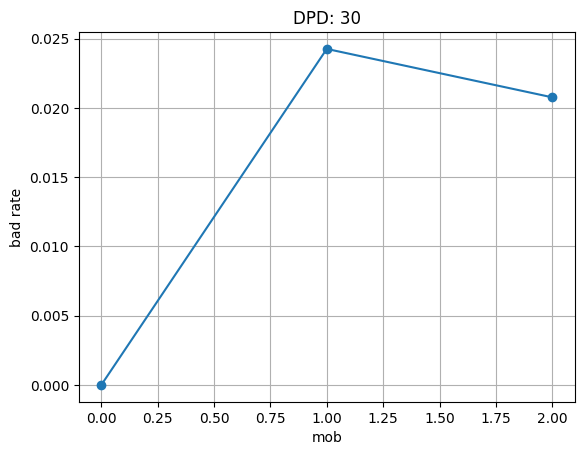

In [29]:
# set dpd label definition
dpd = 30

# Path to the folder containing CSV files
folder_path = silver_lms_daily_directory

# Read all CSV files into a single DataFrame
files_list = [folder_path+os.path.basename(f) for f in glob.glob(os.path.join(folder_path, '*'))]
df = spark.read.option("header", "true").parquet(*files_list)

# filter only completed loans
df = df.filter(col("loan_start_date") < datetime.strptime("2024-01-01", "%Y-%m-%d"))

# create dpd flag if more than dpd
df = df.withColumn("dpd_flag", F.when(col("dpd") >= dpd, 1).otherwise(0))

# actual bads 
actual_bads_df = df.filter(col("installment_num") == 10)

# prepare for analysis
# df = df.filter(col("installment_num") < 10)

# visualise bad rate
pdf = df.toPandas()

# Group by col_A and count occurrences in col_B
grouped = pdf.groupby('mob')['dpd_flag'].mean()

# Sort the index (x-axis) of the grouped DataFrame
grouped = grouped.sort_index()

# Plotting
grouped.plot(kind='line', marker='o')

plt.title('DPD: '+ str(dpd))
plt.xlabel('mob')
plt.ylabel('bad rate')
plt.grid(True)
plt.show()


In [30]:
df.show()

+--------------------+-----------+---------------+------+---------------+--------+-------+--------+-----------+-------+-------------+---+-------------------+-----------------+---+--------+
|             loan_id|Customer_ID|loan_start_date|tenure|installment_num|loan_amt|due_amt|paid_amt|overdue_amt|balance|snapshot_date|mob|installments_missed|first_missed_date|dpd|dpd_flag|
+--------------------+-----------+---------------+------+---------------+--------+-------+--------+-----------+-------+-------------+---+-------------------+-----------------+---+--------+
|CUS_0x1037_2023_0...| CUS_0x1037|     2023-01-01|    10|              2| 10000.0| 1000.0|  1000.0|        0.0| 8000.0|   2023-03-01|  2|                  0|             NULL|  0|       0|
|CUS_0x1069_2023_0...| CUS_0x1069|     2023-01-01|    10|              2| 10000.0| 1000.0|  1000.0|        0.0| 8000.0|   2023-03-01|  2|                  0|             NULL|  0|       0|
|CUS_0x10aa_2023_0...| CUS_0x10aa|     2023-02-01|    1

## Build gold table for labels

In [34]:
# create bronze datalake
gold_label_store_directory = "datamart/gold/label_store/"

if not os.path.exists(gold_label_store_directory):
    os.makedirs(gold_label_store_directory)
    
gold_feature_store_directory = "datamart/gold/feature_store/"
if not os.path.exists(gold_feature_store_directory):
    os.makedirs(gold_feature_store_directory)

In [48]:
import importlib
importlib.reload(utils.data_processing_gold)

<module 'utils.data_processing_gold' from '/app/utils/data_processing_gold.py'>

In [49]:
# run gold feature store backfill
for date_str in dates_str_lst:
    utils.data_processing_gold.process_feature_store(date_str, silver_attributes_daily_directory, silver_financials_daily_directory,
                       silver_clickstream_daily_directory,
                       gold_feature_store_directory, spark)

attributes: 1537 financials: 1537 clickstream: 8974
final row count: 1537
saved to: datamart/gold/feature_store/gold_feature_store_2023_01_01.parquet
attributes: 1537 financials: 1537 clickstream: 8974
final row count: 1537
saved to: datamart/gold/feature_store/gold_feature_store_2023_02_01.parquet
attributes: 1537 financials: 1537 clickstream: 8974
final row count: 1537
saved to: datamart/gold/feature_store/gold_feature_store_2023_03_01.parquet


In [53]:
utils.data_processing_gold.process_feature_store('2023-02-01', silver_attributes_daily_directory, silver_financials_daily_directory,
                       silver_clickstream_daily_directory,
                       gold_feature_store_directory, spark).toPandas()

attributes: 1537 financials: 1537 clickstream: 8974
final row count: 1537
saved to: datamart/gold/feature_store/gold_feature_store_2023_02_01.parquet


,Customer_ID,fe_1,fe_2,fe_3,fe_4,fe_5,fe_6,fe_7,fe_8,fe_9,...,n_Student_Loan,Total_Loans,n_secured,n_unsecured,n_distinct_loan_types,debt_to_income,emi_to_income,Spend_Level,Payment_Value,Credit_Mix_MinAmt
0,CUS_0x1037,55,96,74,171,-69,-103,86,178,42,...,0,4,3,1,3,0.041642,0.031111,Low,Small,Good_No
1,CUS_0x1069,100,-115,50,246,140,160,122,112,14,...,0,3,1,1,3,0.003561,0.029147,High,Small,Standard_Yes
2,CUS_0x114a,142,106,143,155,153,121,64,17,-2,...,1,2,1,1,2,0.041973,0.016498,Low,Small,Good_No
3,CUS_0x1184,130,171,155,101,41,127,0,150,65,...,1,3,1,2,3,0.035600,0.030509,Unknown,Unknown,Good_No
4,CUS_0x1297,60,-18,113,166,112,91,80,185,215,...,1,9,2,7,6,0.067832,0.060694,High,Medium,Bad_Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1532,CUS_0xd7c,99,-61,55,106,164,47,11,140,164,...,0,9,4,3,7,0.071315,0.055456,High,Medium,Bad_Yes
1533,CUS_0xdbf,183,49,-24,208,89,-82,96,168,239,...,0,1,0,0,1,0.001005,0.009320,High,Large,__Yes
1534,CUS_0xdea,16,93,270,-120,142,137,324,80,154,...,0,1,0,0,1,0.062835,0.009287,High,Medium,__No
1535,CUS_0xec8,186,55,64,56,98,204,100,47,115,...,0,1,1,0,1,0.010179,0.004731,High,Small,__Yes


In [22]:
utils.data_processing_gold.process_feature_store(date_str, silver_attributes_daily_directory, silver_financials_daily_directory,
                       silver_clickstream_daily_directory, gold_label_store_directory, spark).dtypes


attributes: 11974 financials: 11974 clickstream: 8974
final row count: 8974 (should equal the click row count after the cutoff filter)
saved to: datamart/gold/label_store/gold_ft_store2023_03_01.parquet


[('Customer_ID', 'string'),
 ('fe_1', 'int'),
 ('fe_2', 'int'),
 ('fe_3', 'int'),
 ('fe_4', 'int'),
 ('fe_5', 'int'),
 ('fe_6', 'int'),
 ('fe_7', 'int'),
 ('fe_8', 'int'),
 ('fe_9', 'int'),
 ('fe_10', 'int'),
 ('fe_11', 'int'),
 ('fe_12', 'int'),
 ('fe_13', 'int'),
 ('fe_14', 'int'),
 ('fe_15', 'int'),
 ('fe_16', 'int'),
 ('fe_17', 'int'),
 ('fe_18', 'int'),
 ('fe_19', 'int'),
 ('fe_20', 'int'),
 ('snapshot_date', 'date'),
 ('Age', 'int'),
 ('Occupation', 'string'),
 ('Annual_Income', 'decimal(10,2)'),
 ('Monthly_Inhand_Salary', 'decimal(10,2)'),
 ('Num_Bank_Accounts', 'int'),
 ('Num_Credit_Card', 'int'),
 ('Interest_Rate', 'int'),
 ('Num_of_Loan', 'int'),
 ('Type_of_Loan', 'string'),
 ('Delay_from_due_date', 'int'),
 ('Num_of_Delayed_Payment', 'int'),
 ('Changed_Credit_Limit', 'decimal(10,2)'),
 ('Num_Credit_Inquiries', 'int'),
 ('Credit_Mix', 'string'),
 ('Outstanding_Debt', 'decimal(10,2)'),
 ('Credit_Utilization_Ratio', 'decimal(10,2)'),
 ('Credit_History_Age', 'string'),
 ('Paymen

In [51]:
# run gold feature store backfill
for date_str in dates_str_lst:
    utils.data_processing_gold.process_label_store(date_str, silver_lms_daily_directory, gold_label_store_directory, spark)

loaded from: datamart/silver/lms_loan_daily/silver_loan_daily_2023_01_01.parquet row count: 530
final row count: 530 (should equal the lms row count after the cutoff filter)
saved to: datamart/gold/label_store/gold_label_store_2023_01_01.parquet
loaded from: datamart/silver/lms_loan_daily/silver_loan_daily_2023_02_01.parquet row count: 1031
final row count: 1031 (should equal the lms row count after the cutoff filter)
saved to: datamart/gold/label_store/gold_label_store_2023_02_01.parquet
loaded from: datamart/silver/lms_loan_daily/silver_loan_daily_2023_03_01.parquet row count: 1537
final row count: 1537 (should equal the lms row count after the cutoff filter)
saved to: datamart/gold/label_store/gold_label_store_2023_03_01.parquet


In [31]:
utils.data_processing_gold.process_label_store(date_str, silver_lms_daily_directory, gold_label_store_directory, spark).toPandas()

loaded from: datamart/silver/lms_loan_daily/silver_loan_daily_2023_03_01.parquet row count: 1537
final row count: 1537 (should equal the lms row count after the cutoff filter)
saved to: datamart/gold/label_store/gold_label_store_2023_03_01.parquet


,loan_id,Customer_ID,mob,installments_missed,first_missed_date,dpd
0,CUS_0x1037_2023_01_01,CUS_0x1037,2,0,None,0
1,CUS_0x1069_2023_01_01,CUS_0x1069,2,0,None,0
2,CUS_0x10aa_2023_02_01,CUS_0x10aa,1,0,None,0
3,CUS_0x10bb_2023_03_01,CUS_0x10bb,0,0,None,0
4,CUS_0x10eb_2023_03_01,CUS_0x10eb,0,0,None,0
...,...,...,...,...,...,...
1532,CUS_0xfa7_2023_03_01,CUS_0xfa7,0,0,None,0
1533,CUS_0xfac_2023_03_01,CUS_0xfac,0,0,None,0
1534,CUS_0xfae_2023_03_01,CUS_0xfae,0,0,None,0
1535,CUS_0xfc9_2023_01_01,CUS_0xfc9,2,1,2023-02-01,28


## inspect label store

In [32]:
folder_path = gold_label_store_directory
files_list = [folder_path+os.path.basename(f) for f in glob.glob(os.path.join(folder_path, '*'))]
df = spark.read.option("header", "true").parquet(*files_list)
print("row_count:",df.count())

df.show()

row_count: 3098
+--------------------+-----------+---+-------------------+-----------------+---+
|             loan_id|Customer_ID|mob|installments_missed|first_missed_date|dpd|
+--------------------+-----------+---+-------------------+-----------------+---+
|CUS_0x1037_2023_0...| CUS_0x1037|  2|                  0|             NULL|  0|
|CUS_0x1069_2023_0...| CUS_0x1069|  2|                  0|             NULL|  0|
|CUS_0x10aa_2023_0...| CUS_0x10aa|  1|                  0|             NULL|  0|
|CUS_0x10bb_2023_0...| CUS_0x10bb|  0|                  0|             NULL|  0|
|CUS_0x10eb_2023_0...| CUS_0x10eb|  0|                  0|             NULL|  0|
|CUS_0x1132_2023_0...| CUS_0x1132|  0|                  0|             NULL|  0|
|CUS_0x1135_2023_0...| CUS_0x1135|  0|                  0|             NULL|  0|
|CUS_0x113e_2023_0...| CUS_0x113e|  1|                  0|             NULL|  0|
|CUS_0x1140_2023_0...| CUS_0x1140|  1|                  0|             NULL|  0|
|CUS_0x114a_

In [33]:
df.printSchema()

root
 |-- loan_id: string (nullable = true)
 |-- Customer_ID: string (nullable = true)
 |-- mob: integer (nullable = true)
 |-- installments_missed: integer (nullable = true)
 |-- first_missed_date: date (nullable = true)
 |-- dpd: integer (nullable = true)

